In [3]:
import sys

# Install dependencies if the notebook is running in Colab
if 'google.colab' in sys.modules:
    !pip install -U -qq tsa-course

In [4]:
# Imports
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from IPython.display import YouTubeVideo
import numpy as np
import pandas as pd
from scipy import signal
from scipy.integrate import cumulative_trapezoid
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.arima_process import arma_generate_sample
from tsa_course.lecture2 import run_sequence_plot
from tsa_course.lecture8 import annotated_sin_plot
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt
from sklearn.metrics import mean_squared_error

In [5]:
# Convenience function that creates both a time domain and frequency domain plot.
def plot_time_freq(t, y):
    # Converts Data into Frequncy Domain
    freq = np.fft.fftfreq(t.size, d=t[1]-t[0])
    Y = abs(np.fft.fft(y))

    # Time domain plot
    plt.figure(figsize = [14,3])
    plt.subplot(1,2,1)
    plt.plot(t,y)
    plt.title('Time Domain')
    plt.xlabel('Time')
    plt.ylabel('Signal')

    # Frequency domain plot
    plt.subplot(1,2,2)
    markerline, stemline, baseline = plt.stem(np.fft.fftshift(freq),np.fft.fftshift(Y),
                                              'k', markerfmt='tab:orange')
    plt.setp(stemline, linewidth = 1.5)
    plt.setp(markerline, markersize = 4)
    plt.title('Frequency Domain')
    plt.xlabel('Frequency')
    plt.xlim(-20, 20)
    plt.ylabel('Absolute FFT')
    plt.grid()

    plt.tight_layout()
    plt.show()

## Exercises

### Упражнение 1

- Объедините (сложите) [синус, тренд и шум](#сигнал-с-трендом-и-шумом), которые мы определили ранее, и получите сигнал, состоящий из:
* Синусоидальной волны, представляющей сезонность.
* Параболической функции, представляющей тренд.
* и равномерно распределенного случайного шума.
- Постройте графики компонентов временной и частотной областей.
- Измените амплитуду компонентов синуса, тренда и шума так, чтобы каждый компонент, в свою очередь, доминировал над другими. Прокомментируйте, как изменяется FT общего сигнала.
- Измените синус в сигнал, который является суммой 2 синусоидальных волн разной амплитуды на 1 и 10 Гц, а также постоянного члена. Постройте графики во временной и частотной областях и прокомментируйте результаты.

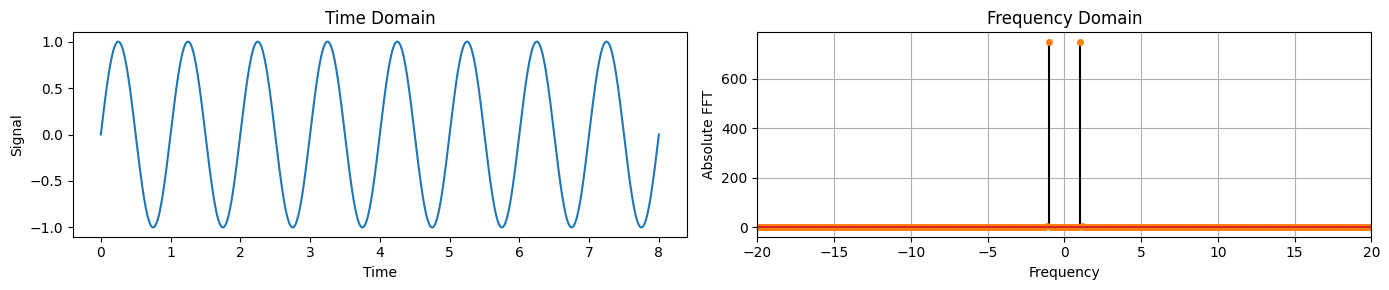

In [6]:
time = np.linspace(0, 8, 1500)
freq = 1

y_sin = np.sin(2 * np.pi * freq * time)
plot_time_freq(time, y_sin)

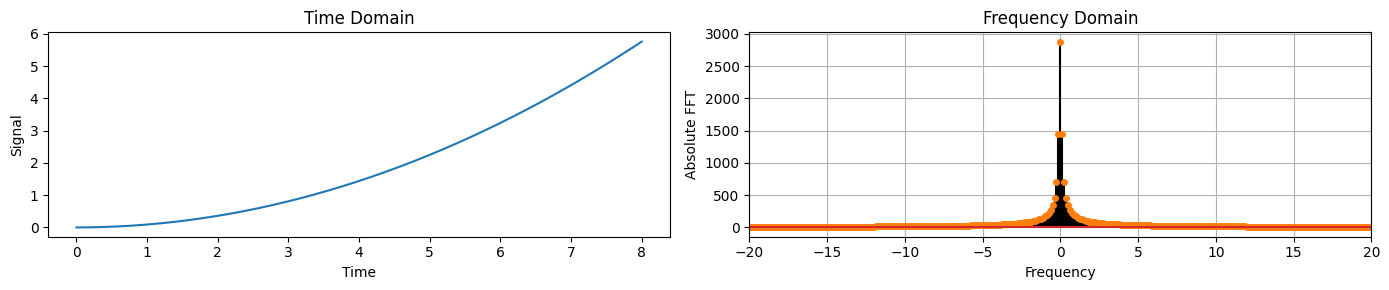

In [7]:
y_trend = (0.3 * time)**2
plot_time_freq(time, y_trend)

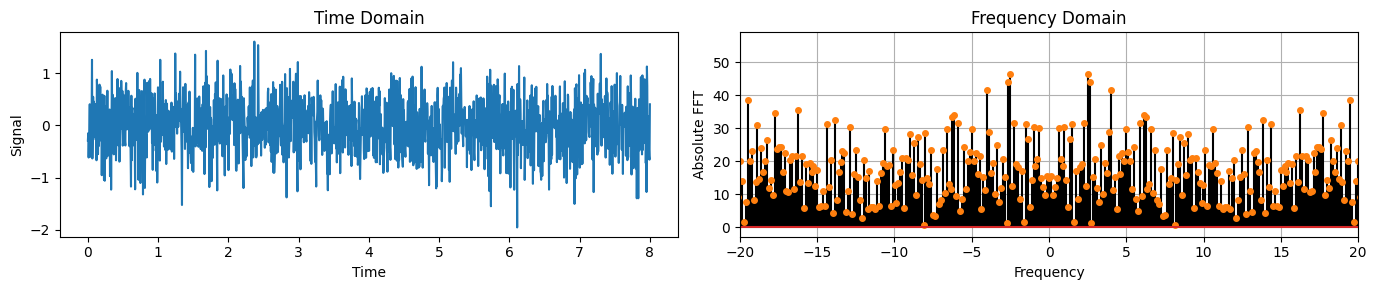

In [8]:
y_noise = 0.5 * np.random.randn(len(time))
plot_time_freq(time, y_noise)

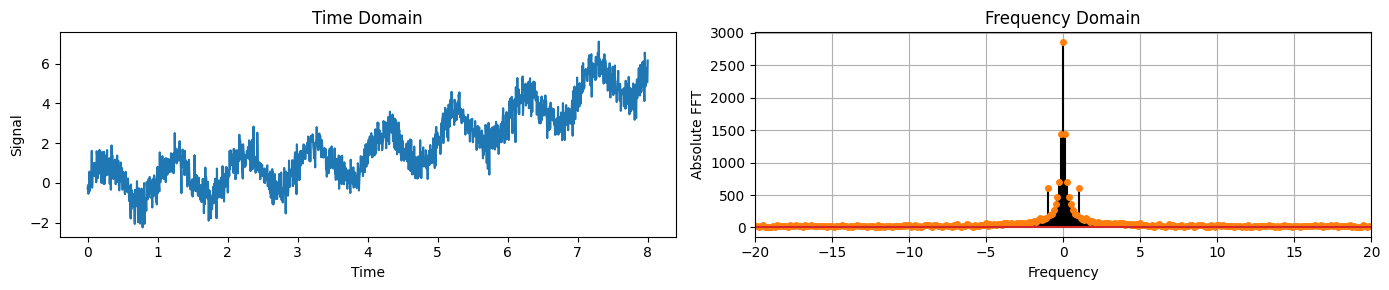

In [9]:
result_signal = y_sin + y_trend + y_noise
plot_time_freq(time, result_signal)

### Exercise 2

- Рассмотрим зашумленный сигнал

In [10]:
def filter_plot(time, y_noisy, y_clean, y_filtered, legend_names, alpha=1):
    plt.figure(figsize=[9,3])
    plt.plot(time, y_noisy, 'k', lw=1)
    plt.plot(time, y_clean, 'tab:blue', lw=3)
    plt.plot(time, np.real(y_filtered), 'tab:red', linestyle='--', lw=3, alpha=alpha)
    plt.legend(legend_names);


def filter_plot_addition(time, y_noisy, y_clean, y_trend, y_filtered, legend_names, alpha=1):
    plt.figure(figsize=[9,3])
    plt.plot(time, y_noisy, 'k', lw=1)
    plt.plot(time, y_clean, 'tab:blue', lw=3)
    plt.plot(time, y_trend, 'tab:green', lw=3)
    plt.plot(time, np.real(y_filtered), 'tab:red', linestyle='--', lw=3, alpha=alpha)
    plt.legend(legend_names);

In [11]:
freq1 = 0.5
freq2 = 2.5
time = np.linspace(0, 5, 512)
y_sine = 2*np.sin(2 * np.pi * freq1 * time)
y_cos = 1.5*np.cos(2 * np.pi * freq2 * time)
y_trend = (0.5 * time)**2
y_noise = 0.8 * np.random.randn(len(time))
y_signal = y_sine + y_cos + y_trend
noisy_signal = y_signal + y_noise

- Примените [фильтр Тьюки](#tukey-filter) к `noisy_signal`.
- Измените значения `alpha` и `div_factor` фильтра, чтобы восстановить чистый сигнал `y_signal`.

Window length: 16


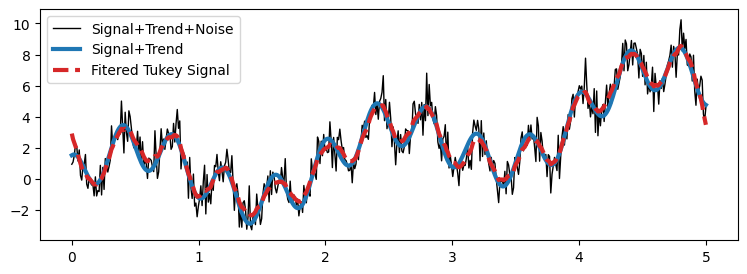

In [12]:
# Filter's parameters
alpha=0.2
div_factor = 32 # use powers of 2
win_len = int(len(time) / div_factor)
print(f"Window length: {win_len}")

# Compute window
window = signal.windows.tukey(win_len, alpha=alpha)

# Compute frequency response
response = np.fft.fft(window, len(time))
response = np.abs(response / abs(response).max())

# БПФ исходного сигнала
Y = (np.fft.fft(noisy_signal))

# восстановленный сигнал (ifft - ОБПФ)
y_tukey = np.fft.ifft(Y*response)

filter_plot(time, noisy_signal, y_signal, y_tukey, ['Signal+Trend+Noise','Signal+Trend','Fitered Tukey Signal'])

для восстановления чистого сигнала наиболее подходят параметры alpha = 0.2, div_factor = 32

### Упражнение 3

- Рассмотрим `noisy_signal` из [Упражнения 2](#exercise-2).
- Теперь ваша задача — восстановить `y_signal` с помощью [фильтра нижних частот Баттерворта](#butterworth-filter).
- Измените порядок фильтра $N$ и частоту среза $\omega_c$ фильтра Баттерворта.
- Какие значения кажутся наилучшими для устранения шума?

In [13]:
fs = 1/(time[1]-time[0])
nyq = 0.5 * fs
omega = freq1 / nyq
print(f"Нормаированная частота для синуса: ω = {omega:.3f}")
omega = freq2 / nyq
print(f"Нормаированная частота для косинуса: ω = {omega:.3f}")

Нормаированная частота для синуса: ω = 0.010
Нормаированная частота для косинуса: ω = 0.049


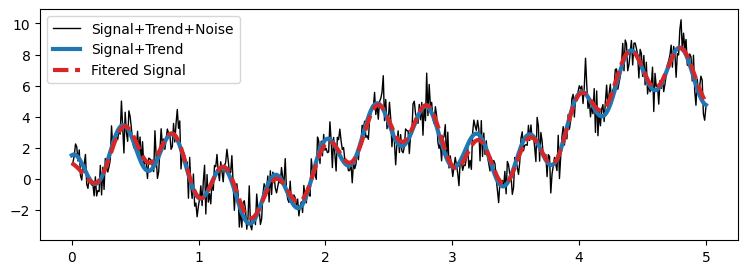

In [14]:
omega_c = 0.06 # берется частота среза 0.06, чтобы пропустить 0.01 и 0.049
B, A = signal.butter(N=6, Wn=omega_c, btype='lowpass')

y_low_butter = signal.filtfilt(B, A, noisy_signal)

filter_plot(time, noisy_signal, y_signal, y_low_butter,
            ['Signal+Trend+Noise','Signal+Trend','Fitered Signal'])

Порядок фильтра N=6 и частота среза 0.06 хорошо подходят для устранения шума.

### Упражнение 4

- Рассмотрим `noisy_signal` из [Упражнения 2](#exercise-2).
- Теперь ваша задача - восстановить `y_signal`, а затем удалить его компонент тренда (`y_trend`).
- Для этого сначала примените [фильтр высоких частот Баттерворта](#high-pass-filters-hpfs).
- Оптимизируйте вручную порядок фильтра $N$ и частоту среза $\omega_c$ фильтра Баттерворта.
- Затем примените LPF каскадно к HPF.
- Результат не должен содержать ни тренда, ни шума.

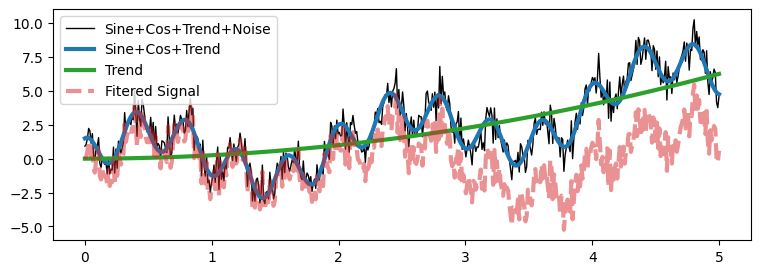

In [15]:
omega_hpf = 0.005 # берется частота среза 0.005, чтобы пропустить 0.01 и 0.049
N_hpf = 2

B, A = signal.butter(N_hpf, omega_hpf, btype = 'highpass', output='ba')


y_high_butter = signal.filtfilt(B, A, noisy_signal)


filter_plot_addition(time, noisy_signal, y_signal, y_trend, y_high_butter,
            ['Sine+Cos+Trend+Noise', 'Sine+Cos+Trend', 'Trend', 'Fitered Signal'], alpha=0.5)

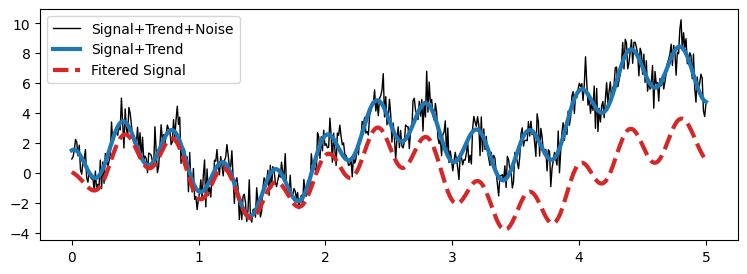

In [16]:
omega_lpf = 0.06 # берется частота среза 0.06, чтобы пропустить 0.01 и 0.049
B, A = signal.butter(N=6, Wn=omega_lpf, btype='lowpass')

y_low_butter = signal.filtfilt(B, A, y_high_butter)

filter_plot(time, noisy_signal, y_signal, y_low_butter,
            ['Signal+Trend+Noise','Signal+Trend','Fitered Signal'])

Тренд и шум исключены из отфильтрованного сигнала.

### Упражнение 5

- Рассмотрим `noisy_signal` из [Упражнения 2](#exercise-2).
- И снова ваша задача - восстановить `y_signal`, а затем удалить его трендовую составляющую (`y_trend`).
- Оптимизируйте вручную порядок фильтра $N$ и частоты среза $\omega_c^\text{LOW}$ и $\omega_c^\text{HIGH}$ [полосового фильтра Баттерворта](#band-pass-filter).
- Сравните результат BPF с тем, что вы получили в [Упражнении 4](#exercise-4), когда вы применили HPF и LPF последовательно.

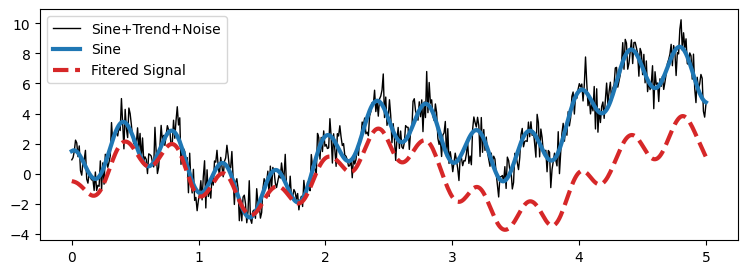

In [17]:
# Band Pass Butterworth filter
N  = 2    # Filter order
omega_c = [0.005, 0.06] # Cutoff frequencies

B, A = signal.butter(N, omega_c, btype = 'bandpass', output='ba')

# Apply the filter
y_band_butter = signal.filtfilt(B, A, noisy_signal)

# plot
filter_plot(time, noisy_signal, y_signal, y_band_butter,
            ['Sine+Trend+Noise','Sine','Fitered Signal'])

### Упражнение 6

- Рассмотрим `noisy_signal` из [Упражнения 2](#exercise-2).
- На этот раз вам придется удалить компонент `y_cos` из сигнала с помощью [полосового заграждающего фильтра](#band-stop-filter).

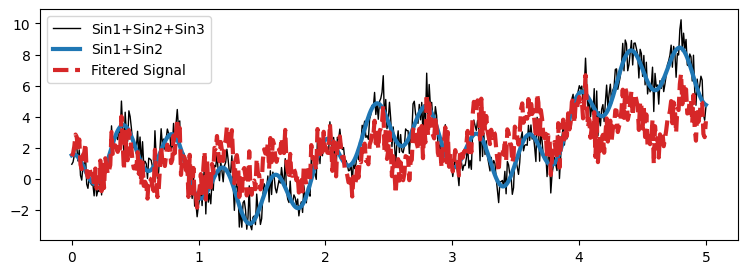

In [18]:
fs = len(time) / (time[-1] - time[0])

# Filter parameters to reject the third sinusoid
lowcut = 0.2  # Just below the third frequency
highcut = 1.5  # Just above the third frequency

# Scale the values by the sampling frequency
nyq = 0.5 * fs
omega_c_low = lowcut / nyq
omega_c_high = highcut / nyq
omega = freq1 / nyq

# Band Stop Butterworth filter
N  = 2    # Filter order
omega_c = [omega_c_low, omega_c_high] # Cutoff frequencies

B, A = signal.butter(N, omega_c, btype = 'bandstop', output='ba')

# Apply the filter
y_stop_butter = signal.filtfilt(B, A, noisy_signal)

# plot
filter_plot(time, noisy_signal, y_signal, y_stop_butter,
            ['Sin1+Sin2+Sin3','Sin1+Sin2','Fitered Signal'])

### Упражнение 7

- Рассмотрим данные CO2, определенные [здесь](#forecast-example-2).
- Разделите данные на обучающие и тестовые.
- Определите оптимальное количество гармоник, которое дает наилучшую MSE на тестовом наборе.